In [1]:
import pandas as pd
import numpy as np


In [2]:
# ==========================================
# CAREFLOW: SYNTHETIC HOSPITAL EVENT LOG
# Generate 5,000 patient visits using Python
# ==========================================

import pandas as pd
import numpy as np
from pathlib import Path

# 1. Set a random seed so results can be reproduced
np.random.seed(42)
rng = np.random.default_rng(42)

# 2. Define the number of patient visits
TOTAL_PATIENTS = 5000

# 3. Define the simulation period
START_DATE = pd.Timestamp("2026-10-05 00:00:00")
END_DATE = pd.Timestamp("2026-11-05 23:59:59")

# 4. Define available staff/resources for each activity
resources = {
    "Registration": ["Registration_01", "Registration_02"],
    "Triage": ["Nurse_01", "Nurse_02", "Nurse_03"],
    "X-Ray": ["Radiographer_01", "Radiographer_02"],
    "Return to Triage": ["Nurse_01", "Nurse_02", "Nurse_03"],
    "Lab Test": ["LabTech_01", "LabTech_02"],
    "Treatment": ["Nurse_01", "Nurse_02"],
    "Doctor Consultation": ["Doctor_01", "Doctor_02", "Doctor_03"],
    "Admission": ["BedManager_01", "BedManager_02"],
    "Discharge": ["Discharge_01", "Discharge_02"]
}

# 5. Define patient categories
patient_categories = ["Adult", "Child", "Older Adult"]
category_probabilities = [0.70, 0.12, 0.18]

# 6. Store all generated events here
all_events = []

# 7. Generate events for each patient visit
for patient_number in range(1, TOTAL_PATIENTS + 1):

    # Create a unique visit ID
    case_id = f"P{patient_number:05d}"

    # Generate the arrival timestamp
    total_seconds = int(
        (END_DATE - START_DATE).total_seconds()
    )

    arrival_time = START_DATE + pd.Timedelta(
        seconds=int(rng.integers(0, total_seconds + 1))
    )

    # Determine the shift from the arrival hour
    hour = arrival_time.hour

    if 6 <= hour < 14:
        shift = "Morning"
    elif 14 <= hour < 22:
        shift = "Afternoon"
    else:
        shift = "Night"

    # Generate patient category
    patient_category = rng.choice(
        patient_categories,
        p=category_probabilities
    )

    department = "Emergency"

    # Record this patient's chronological events
    events = []
    current_time = arrival_time

    # Event 1: Registration
    events.append(("Registration", current_time))

    # Event 2: Triage
    current_time += pd.Timedelta(
        minutes=int(rng.integers(3, 13))
    )
    events.append(("Triage", current_time))

    # Choose the patient's pathway
    pathway = rng.choice(
        [
            "basic",
            "xray",
            "lab",
            "xray_treatment",
            "lab_treatment",
            "xray_lab"
        ],
        p=[0.22, 0.30, 0.12, 0.18, 0.10, 0.08]
    )

    # Event 3: X-Ray, if required
    if pathway in ["xray", "xray_treatment", "xray_lab"]:

        current_time += pd.Timedelta(
            minutes=int(rng.integers(5, 36))
        )
        events.append(("X-Ray", current_time))

        # Simulate the hidden bottleneck:
        # 40% of X-Ray visits return to triage
        if rng.random() < 0.40:

            current_time += pd.Timedelta(
                minutes=int(rng.integers(5, 26))
            )
            events.append(("Return to Triage", current_time))

            # Patient undergoes triage again
            current_time += pd.Timedelta(
                minutes=int(rng.integers(5, 21))
            )
            events.append(("Triage", current_time))

    # Event 4: Lab test, if required
    if pathway in ["lab", "lab_treatment", "xray_lab"]:

        current_time += pd.Timedelta(
            minutes=int(rng.integers(5, 31))
        )
        events.append(("Lab Test", current_time))

    # Event 5: Treatment, if required
    if pathway in ["xray_treatment", "lab_treatment"]:

        current_time += pd.Timedelta(
            minutes=int(rng.integers(5, 31))
        )
        events.append(("Treatment", current_time))

    # Event 6: Doctor consultation
    current_time += pd.Timedelta(
        minutes=int(rng.integers(5, 46))
    )
    events.append(("Doctor Consultation", current_time))

    # Event 7: Admission or discharge
    if rng.random() < 0.08:

        current_time += pd.Timedelta(
            minutes=int(rng.integers(15, 91))
        )
        events.append(("Admission", current_time))

    else:

        current_time += pd.Timedelta(
            minutes=int(rng.integers(5, 31))
        )
        events.append(("Discharge", current_time))

    # Add every event to the main dataset
    for activity, timestamp in events:

        resource = rng.choice(resources[activity])

        all_events.append({
            "case_id": case_id,
            "activity": activity,
            "timestamp": timestamp,
            "department": department,
            "shift": shift,
            "patient_category": patient_category,
            "resource": resource
        })

# 8. Convert the generated records into a DataFrame
df = pd.DataFrame(all_events)

# 9. Sort events chronologically within each patient visit
df = df.sort_values(
    ["case_id", "timestamp"]
).reset_index(drop=True)

# 10. Save the raw event log as a CSV file
output_file = Path("careflow_raw_events_5000_visits.csv")

df.to_csv(
    output_file,
    index=False,
    date_format="%Y-%m-%d %H:%M:%S"
)

# 11. Validate the generated dataset
print("CARE­FLOW DATASET CREATED SUCCESSFULLY")
print("--------------------------------------")
print("Patient visits:", df["case_id"].nunique())
print("Total event records:", len(df))
print("Total columns:", len(df.columns))
print("Average events per visit:",
      round(df.groupby("case_id").size().mean(), 2))
print("Missing values:", df.isnull().sum().sum())
print("CSV saved to:", output_file.resolve())

print("\nActivity counts:")
print(df["activity"].value_counts())

# 12. Check the simulated return-to-triage rate
xray_cases = df.loc[
    df["activity"] == "X-Ray", "case_id"
].nunique()

return_cases = df.loc[
    df["activity"] == "Return to Triage", "case_id"
].nunique()

if xray_cases > 0:
    return_rate = return_cases / xray_cases * 100
    print(
        "\nReturn-to-triage rate among X-Ray visits:",
        round(return_rate, 2), "%"
    )

print("\nFirst 10 event records:")
print(df.head(10).to_string(index=False))

CARE­FLOW DATASET CREATED SUCCESSFULLY
--------------------------------------
Patient visits: 5000
Total event records: 27962
Total columns: 7
Average events per visit: 5.59
Missing values: 0
CSV saved to: C:\Users\suraj\project\CareFlow-Clinical-Pathway\careflow_raw_events_5000_visits.csv

Activity counts:
activity
Triage                 6141
Registration           5000
Doctor Consultation    5000
Discharge              4601
X-Ray                  2815
Lab Test               1476
Treatment              1389
Return to Triage       1141
Admission               399
Name: count, dtype: int64

Return-to-triage rate among X-Ray visits: 40.53 %

First 10 event records:
case_id            activity           timestamp department     shift patient_category        resource
 P00001        Registration 2026-10-07 20:32:41  Emergency Afternoon            Adult Registration_02
 P00001              Triage 2026-10-07 20:42:41  Emergency Afternoon            Adult        Nurse_03
 P00001            Lab

In [3]:
df

,case_id,activity,timestamp,department,shift,patient_category,resource
0,P00001,Registration,2026-10-07 20:32:41,Emergency,Afternoon,Adult,Registration_02
1,P00001,Triage,2026-10-07 20:42:41,Emergency,Afternoon,Adult,Nurse_03
2,P00001,Lab Test,2026-10-07 20:49:41,Emergency,Afternoon,Adult,LabTech_02
3,P00001,Treatment,2026-10-07 21:12:41,Emergency,Afternoon,Adult,Nurse_02
4,P00001,Doctor Consultation,2026-10-07 21:25:41,Emergency,Afternoon,Adult,Doctor_02
...,...,...,...,...,...,...,...
27957,P04999,Discharge,2026-11-04 03:43:30,Emergency,Night,Adult,Discharge_02
27958,P05000,Registration,2026-10-28 14:40:44,Emergency,Afternoon,Adult,Registration_02
27959,P05000,Triage,2026-10-28 14:46:44,Emergency,Afternoon,Adult,Nurse_03
27960,P05000,Doctor Consultation,2026-10-28 14:56:44,Emergency,Afternoon,Adult,Doctor_02


In [4]:
df["patient_category"].unique()

<ArrowStringArray>
['Adult', 'Child', 'Older Adult']
Length: 3, dtype: str

In [5]:
df.to_csv('careflow_raw_events_5000_visits.csv', index=False)

In [6]:
pwd 

'C:\\Users\\suraj\\project\\CareFlow-Clinical-Pathway'

In [7]:
import sys
import pandas as pd
import numpy as np

print("Python version:", sys.version)
print("Python location:", sys.executable)
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

Python version: 3.13.9 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 19:09:58) [MSC v.1929 64 bit (AMD64)]
Python location: C:\Users\suraj\ad\python.exe
Pandas version: 3.0.6
NumPy version: 2.5.4


In [8]:

#%pip install pm4py


In [9]:

import pm4py

print("PM4Py version:", pm4py.__version__)
print("PM4Py installed successfully!")




  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing




PM4Py version: 2.7.23.9
PM4Py installed successfully!


In [10]:

import pandas as pd

df = pd.read_csv("careflow_raw_events_5000_visits.csv")

print("Dataset loaded successfully!")
print("Rows:", len(df))
print("Columns:", df.columns.tolist())
print(df.head())


Dataset loaded successfully!
Rows: 27962
Columns: ['case_id', 'activity', 'timestamp', 'department', 'shift', 'patient_category', 'resource']
  case_id             activity            timestamp department      shift  \
0  P00001         Registration  2026-10-07 20:32:41  Emergency  Afternoon   
1  P00001               Triage  2026-10-07 20:42:41  Emergency  Afternoon   
2  P00001             Lab Test  2026-10-07 20:49:41  Emergency  Afternoon   
3  P00001            Treatment  2026-10-07 21:12:41  Emergency  Afternoon   
4  P00001  Doctor Consultation  2026-10-07 21:25:41  Emergency  Afternoon   

  patient_category         resource  
0            Adult  Registration_02  
1            Adult         Nurse_03  
2            Adult       LabTech_02  
3            Adult         Nurse_02  
4            Adult        Doctor_02  


In [11]:

#%pip install pandas numpy matplotlib pm4py google-cloud-bigquery db-dtypes


In [12]:

import pandas as pd
import numpy as np
import pm4py

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("PM4Py:", pm4py.__version__)
print("Libraries installed successfully!")


Pandas: 3.0.6
NumPy: 2.5.4
PM4Py: 2.7.23.9
Libraries installed successfully!


In [13]:
from google.cloud import bigquery

PROJECT_ID = "polished-trail-511415-r4"

client = bigquery.Client(project=PROJECT_ID)

print("Connected to BigQuery successfully!")

    

Connected to BigQuery successfully!


In [14]:
query = """
SELECT
    case_id,
    activity,
    timestamp,
    department,
    shift,
    patient_category,
    resource
FROM `polished-trail-511415-r4.careflow.clean_events`
ORDER BY case_id, timestamp
"""

df = client.query(query).to_dataframe()

print("Total events:", len(df))
print("Total patient visits:", df["case_id"].nunique())

display(df.head(10))


C:\Users\suraj\ad\Lib\site-packages\google\cloud\bigquery\table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


Total events: 27962
Total patient visits: 5000


,case_id,activity,timestamp,department,shift,patient_category,resource
0,P00001,Registration,2026-10-07 20:32:41+00:00,Emergency,Afternoon,Adult,Registration_02
1,P00001,Triage,2026-10-07 20:42:41+00:00,Emergency,Afternoon,Adult,Nurse_03
2,P00001,Lab Test,2026-10-07 20:49:41+00:00,Emergency,Afternoon,Adult,LabTech_02
3,P00001,Treatment,2026-10-07 21:12:41+00:00,Emergency,Afternoon,Adult,Nurse_02
4,P00001,Doctor Consultation,2026-10-07 21:25:41+00:00,Emergency,Afternoon,Adult,Doctor_02
5,P00001,Discharge,2026-10-07 21:32:41+00:00,Emergency,Afternoon,Adult,Discharge_01
6,P00002,Registration,2026-10-31 20:55:35+00:00,Emergency,Afternoon,Adult,Registration_01
7,P00002,Triage,2026-10-31 21:02:35+00:00,Emergency,Afternoon,Adult,Nurse_02
8,P00002,X-Ray,2026-10-31 21:31:35+00:00,Emergency,Afternoon,Adult,Radiographer_02
9,P00002,Lab Test,2026-10-31 21:52:35+00:00,Emergency,Afternoon,Adult,LabTech_01


In [15]:
# 1. Check missing values
print("=== Missing Values ===")
display(df.isnull().sum())

# 2. Check duplicate events
print("\n=== Duplicate Events ===")
print(
    "Duplicates:",
    df.duplicated(
        subset=["case_id", "activity", "timestamp"]
    ).sum()
)

# 3. Count each activity
print("\n=== Activity Counts ===")
display(df["activity"].value_counts())

# 4. Check number of events per visit
print("\n=== Events per Visit ===")
display(df.groupby("case_id").size().describe())


=== Missing Values ===


case_id             0
activity            0
timestamp           0
department          0
shift               0
patient_category    0
resource            0
dtype: int64


=== Duplicate Events ===
Duplicates: 0

=== Activity Counts ===


activity
Triage                 6141
Registration           5000
Doctor Consultation    5000
Discharge              4601
X-Ray                  2815
Lab Test               1476
Treatment              1389
Return to Triage       1141
Admission               399
Name: count, dtype: int64


=== Events per Visit ===


count    5000.000000
mean        5.592400
std         1.248749
min         4.000000
25%         5.000000
50%         5.000000
75%         6.000000
max         8.000000
dtype: float64

In [16]:
import pandas as pd
import pm4py

# Convert timestamps and order events chronologically
df["timestamp"] = pd.to_datetime(df["timestamp"], utc=True)
df = df.sort_values(
    ["case_id", "timestamp"]
).reset_index(drop=True)

# Check the event log structure
print("PM4Py version:", pm4py.__version__)
print("Events:", len(df))
print("Patient visits:", df["case_id"].nunique())
print("Timestamp type:", df["timestamp"].dtype)

display(df.head())


PM4Py version: 2.7.23.9
Events: 27962
Patient visits: 5000
Timestamp type: datetime64[us, UTC]


,case_id,activity,timestamp,department,shift,patient_category,resource
0,P00001,Registration,2026-10-07 20:32:41+00:00,Emergency,Afternoon,Adult,Registration_02
1,P00001,Triage,2026-10-07 20:42:41+00:00,Emergency,Afternoon,Adult,Nurse_03
2,P00001,Lab Test,2026-10-07 20:49:41+00:00,Emergency,Afternoon,Adult,LabTech_02
3,P00001,Treatment,2026-10-07 21:12:41+00:00,Emergency,Afternoon,Adult,Nurse_02
4,P00001,Doctor Consultation,2026-10-07 21:25:41+00:00,Emergency,Afternoon,Adult,Doctor_02


In [17]:
print("Missing values:")
display(df.isnull().sum())

print("Events per patient visit:")
display(df.groupby("case_id").size().describe())

print("Activities in the dataset:")
display(df["activity"].value_counts())


Missing values:


case_id             0
activity            0
timestamp           0
department          0
shift               0
patient_category    0
resource            0
dtype: int64

Events per patient visit:


count    5000.000000
mean        5.592400
std         1.248749
min         4.000000
25%         5.000000
50%         5.000000
75%         6.000000
max         8.000000
dtype: float64

Activities in the dataset:


activity
Triage                 6141
Registration           5000
Doctor Consultation    5000
Discharge              4601
X-Ray                  2815
Lab Test               1476
Treatment              1389
Return to Triage       1141
Admission               399
Name: count, dtype: int64

In [18]:
#process mining

In [19]:
#Calculate how many visits return to triage

returned_cases = df.loc[
    df["activity"] == "Return to Triage",
    "case_id"
].nunique()

total_cases = df["case_id"].nunique()
return_percentage = returned_cases / total_cases * 100

print("Visits with a return to triage:", returned_cases)
print("Total visits:", total_cases)
print(f"Percentage of visits: {return_percentage:.2f}%")


Visits with a return to triage: 1141
Total visits: 5000
Percentage of visits: 22.82%


In [20]:

import pandas as pd
import pm4py

# Make sure timestamps are in datetime format
df["timestamp"] = pd.to_datetime(df["timestamp"], utc=True)

# Sort events in chronological order for each patient
df = df.sort_values(
    ["case_id", "timestamp"]
).reset_index(drop=True)

# Rename columns to PM4Py standard names
event_log_df = df.rename(columns={
    "case_id": "case:concept:name",
    "activity": "concept:name",
    "timestamp": "time:timestamp"
}).copy()

# Format the event log
event_log_df = pm4py.format_dataframe(
    event_log_df,
    case_id="case:concept:name",
    activity_key="concept:name",
    timestamp_key="time:timestamp"
)

print("Event log prepared successfully!")
print("Total events:", len(event_log_df))
print("Unique patient visits:",
      event_log_df["case:concept:name"].nunique())

display(event_log_df.head())



Event log prepared successfully!
Total events: 27962
Unique patient visits: 5000


,case:concept:name,concept:name,time:timestamp,department,shift,patient_category,resource,@@index,@@case_index
0,P00001,Registration,2026-10-07 20:32:41+00:00,Emergency,Afternoon,Adult,Registration_02,0,0
1,P00001,Triage,2026-10-07 20:42:41+00:00,Emergency,Afternoon,Adult,Nurse_03,1,0
2,P00001,Lab Test,2026-10-07 20:49:41+00:00,Emergency,Afternoon,Adult,LabTech_02,2,0
3,P00001,Treatment,2026-10-07 21:12:41+00:00,Emergency,Afternoon,Adult,Nurse_02,3,0
4,P00001,Doctor Consultation,2026-10-07 21:25:41+00:00,Emergency,Afternoon,Adult,Doctor_02,4,0


In [22]:
import shutil

print(shutil.which("dot"))

C:\Users\suraj\Downloads\windows_10_cmake_Release_Graphviz-16.1.0-win64\Graphviz-16.1.0-win64\bin\dot.EXE


In [23]:
import pandas as pd
import pm4py

# Check that the event data exists
print(df.shape)
print(df.columns.tolist())

(27962, 7)
['case_id', 'activity', 'timestamp', 'department', 'shift', 'patient_category', 'resource']


In [24]:
# Prepare the data for PM4Py
df["timestamp"] = pd.to_datetime(df["timestamp"], utc=True)
df = df.sort_values(["case_id", "timestamp"]).reset_index(drop=True)

event_log_df = df.rename(columns={
    "case_id": "case:concept:name",
    "activity": "concept:name",
    "timestamp": "time:timestamp"
}).copy()

event_log_df = pm4py.format_dataframe(
    event_log_df,
    case_id="case:concept:name",
    activity_key="concept:name",
    timestamp_key="time:timestamp"
)

# Convert the dataframe to an event log
log = pm4py.convert_to_event_log(event_log_df)

print("Event log created successfully!")
print("Number of events:", len(event_log_df))

Event log created successfully!
Number of events: 27962


In [25]:
from pm4py.algo.discovery.inductive import algorithm as inductive_miner
from pm4py.objects.conversion.process_tree import converter as pt_converter
from pm4py.visualization.petri_net import visualizer as pn_visualizer

# Discover the process tree
process_tree = inductive_miner.apply(log)

print("Process tree discovered successfully!")

# Convert the process tree into a Petri net
net, initial_marking, final_marking = pt_converter.apply(process_tree)

print("Petri net created successfully!")

Process tree discovered successfully!
Petri net created successfully!


In [26]:
import os
import shutil

print("Graphviz found at:", shutil.which("dot"))

Graphviz found at: C:\Users\suraj\Downloads\windows_10_cmake_Release_Graphviz-16.1.0-win64\Graphviz-16.1.0-win64\bin\dot.EXE


In [27]:
from pm4py.algo.discovery.inductive import algorithm as inductive_miner
from pm4py.objects.conversion.process_tree import converter as pt_converter
from pm4py.visualization.petri_net import visualizer as pn_visualizer

# Discover the process tree
process_tree = inductive_miner.apply(log)
print("Process tree discovered successfully!")

# Convert it into a Petri net
net, initial_marking, final_marking = pt_converter.apply(process_tree)
print("Petri net created successfully!")

Process tree discovered successfully!
Petri net created successfully!


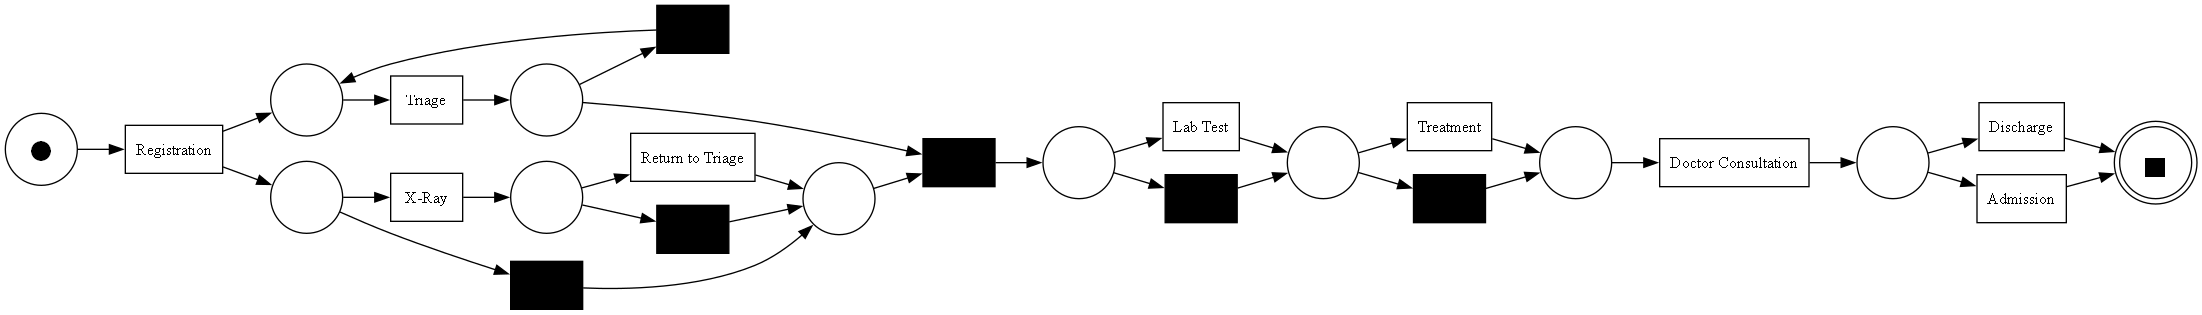

In [28]:
gviz = pn_visualizer.apply(
    net,
    initial_marking,
    final_marking
)

pn_visualizer.view(gviz)

In [29]:
# Count visits that returned to triage
returned_cases = df.loc[
    df["activity"] == "Return to Triage",
    "case_id"
].nunique()

# Count all visits
total_cases = df["case_id"].nunique()

# Calculate percentage
return_percentage = (returned_cases / total_cases) * 100

print("Total visits:", total_cases)
print("Visits with Return to Triage:", returned_cases)
print(f"Percentage of visits that returned to triage: {return_percentage:.2f}%")

Total visits: 5000
Visits with Return to Triage: 1141
Percentage of visits that returned to triage: 22.82%


In [30]:
# Sort events chronologically within each visit
df = df.sort_values(
    ["case_id", "timestamp"]
).copy()

# Get the next activity and its timestamp
df["next_activity"] = (
    df.groupby("case_id")["activity"].shift(-1)
)

df["next_timestamp"] = (
    df.groupby("case_id")["timestamp"].shift(-1)
)

# Calculate elapsed time in minutes
df["elapsed_minutes"] = (
    df["next_timestamp"] - df["timestamp"]
).dt.total_seconds() / 60

# Name each transition
df["transition"] = (
    df["activity"] + " → " + df["next_activity"]
)

display(df[[
    "case_id",
    "activity",
    "timestamp",
    "next_activity",
    "elapsed_minutes",
    "transition"
]].head(15))

,case_id,activity,timestamp,next_activity,elapsed_minutes,transition
0,P00001,Registration,2026-10-07 20:32:41+00:00,Triage,10.0,Registration → Triage
1,P00001,Triage,2026-10-07 20:42:41+00:00,Lab Test,7.0,Triage → Lab Test
2,P00001,Lab Test,2026-10-07 20:49:41+00:00,Treatment,23.0,Lab Test → Treatment
3,P00001,Treatment,2026-10-07 21:12:41+00:00,Doctor Consultation,13.0,Treatment → Doctor Consultation
4,P00001,Doctor Consultation,2026-10-07 21:25:41+00:00,Discharge,7.0,Doctor Consultation → Discharge
5,P00001,Discharge,2026-10-07 21:32:41+00:00,NaN,NaN,NaN
6,P00002,Registration,2026-10-31 20:55:35+00:00,Triage,7.0,Registration → Triage
7,P00002,Triage,2026-10-31 21:02:35+00:00,X-Ray,29.0,Triage → X-Ray
8,P00002,X-Ray,2026-10-31 21:31:35+00:00,Lab Test,21.0,X-Ray → Lab Test
9,P00002,Lab Test,2026-10-31 21:52:35+00:00,Doctor Consultation,27.0,Lab Test → Doctor Consultation


In [31]:
transition_summary = (
    df.dropna(subset=["elapsed_minutes", "next_activity"])
      .groupby("transition")["elapsed_minutes"]
      .agg(
          event_count="count",
          mean_minutes="mean",
          median_minutes="median"
      )
      .sort_values("median_minutes", ascending=False)
)

display(transition_summary.round(2))

,event_count,mean_minutes,median_minutes
transition,,,
Doctor Consultation → Admission,399,51.84,51.0
Treatment → Doctor Consultation,1389,25.15,25.0
Triage → Doctor Consultation,1746,25.08,25.0
X-Ray → Doctor Consultation,887,24.93,25.0
Lab Test → Doctor Consultation,978,24.45,24.0
Triage → X-Ray,2815,19.86,20.0
X-Ray → Lab Test,241,17.83,19.0
Triage → Treatment,345,18.18,18.0
Doctor Consultation → Discharge,4601,17.59,18.0


In [32]:
    
#  Inspect visits that return to triage after X-Ray

returned_path = df[
    df["activity"] == "Return to Triage"
].copy()

# Find the activity immediately before each return event
returned_path["previous_activity"] = (
    df.groupby("case_id")["activity"].shift(1)
    .loc[returned_path.index]
)

print("Return to Triage event count:", len(returned_path))

print("\nActivity immediately before Return to Triage:")
display(
    returned_path["previous_activity"]
    .value_counts()
    .rename_axis("previous_activity")
    .to_frame("event_count")
)

# Show example pathways
returned_case_ids = returned_path["case_id"].drop_duplicates().head(5)

display(
    df[df["case_id"].isin(returned_case_ids)][
        ["case_id", "activity", "timestamp"]
    ].sort_values(["case_id", "timestamp"])
)


Return to Triage event count: 1141

Activity immediately before Return to Triage:


,event_count
previous_activity,
X-Ray,1141


,case_id,activity,timestamp
17,P00004,Registration,2026-10-22 11:45:55+00:00
18,P00004,Triage,2026-10-22 11:49:55+00:00
19,P00004,X-Ray,2026-10-22 12:05:55+00:00
20,P00004,Return to Triage,2026-10-22 12:30:55+00:00
21,P00004,Triage,2026-10-22 12:49:55+00:00
22,P00004,Treatment,2026-10-22 13:03:55+00:00
23,P00004,Doctor Consultation,2026-10-22 13:11:55+00:00
24,P00004,Discharge,2026-10-22 13:28:55+00:00
57,P00011,Registration,2026-10-12 15:22:20+00:00
58,P00011,Triage,2026-10-12 15:28:20+00:00


In [33]:

#  Compare total visit duration

# Ensure events are sorted by visit and timestamp
df = df.sort_values(["case_id", "timestamp"]).copy()

# Calculate first and last recorded timestamp for each visit
visit_summary = (
    df.groupby("case_id")
      .agg(
          start_time=("timestamp", "min"),
          end_time=("timestamp", "max"),
          event_count=("activity", "count")
      )
      .reset_index()
)

# Calculate total recorded visit duration in minutes
visit_summary["duration_minutes"] = (
    visit_summary["end_time"] - visit_summary["start_time"]
).dt.total_seconds() / 60

# Identify visits containing Return to Triage
returned_ids = set(
    df.loc[df["activity"] == "Return to Triage", "case_id"]
)

visit_summary["returned_to_triage"] = (
    visit_summary["case_id"].isin(returned_ids)
)

# Compare visits in the two groups
duration_comparison = (
    visit_summary.groupby("returned_to_triage")["duration_minutes"]
    .agg(
        visit_count="count",
        mean_minutes="mean",
        median_minutes="median",
        min_minutes="min",
        max_minutes="max"
    )
    .rename(index={
        False: "No return to triage",
        True: "Return to triage"
    })
)

display(duration_comparison.round(2))


,visit_count,mean_minutes,median_minutes,min_minutes,max_minutes
returned_to_triage,,,,,
No return to triage,3859,72.09,70.0,16.0,174.0
Return to triage,1141,107.78,106.0,49.0,201.0


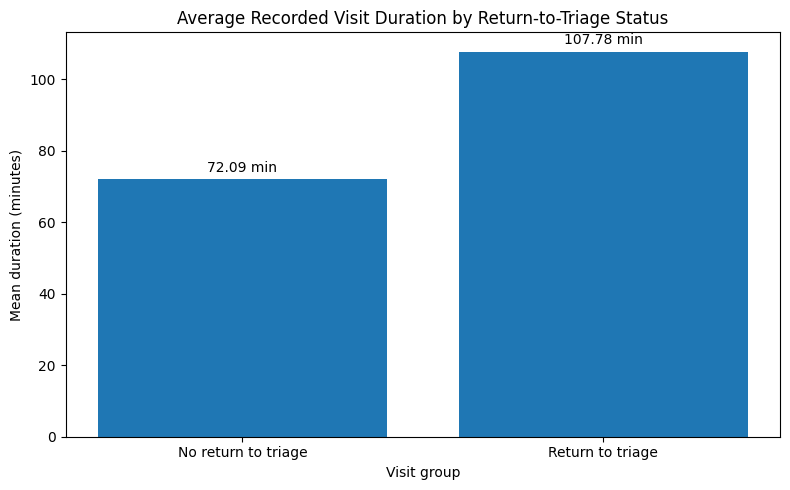

In [34]:

import matplotlib.pyplot as plt

# Values from your visit_summary comparison
groups = ["No return to triage", "Return to triage"]
mean_durations = [72.09, 107.78]

plt.figure(figsize=(8, 5))
bars = plt.bar(groups, mean_durations)

plt.title("Average Recorded Visit Duration by Return-to-Triage Status")
plt.ylabel("Mean duration (minutes)")
plt.xlabel("Visit group")

# Display the values above the bars
for bar, value in zip(bars, mean_durations):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 2,
        f"{value:.2f} min",
        ha="center"
    )

plt.tight_layout()
plt.show()


In [35]:

# Attach shift information to each visit
visit_shift = (
    df.groupby("case_id")
      .agg(shift=("shift", "first"))
      .reset_index()
)

visit_analysis = visit_summary.merge(
    visit_shift,
    on="case_id",
    how="left"
)

# Compare return rates and durations by shift
shift_summary = (
    visit_analysis.groupby("shift")
    .agg(
        total_visits=("case_id", "nunique"),
        return_visits=("returned_to_triage", "sum"),
        mean_duration=("duration_minutes", "mean")
    )
)

shift_summary["return_rate_pct"] = (
    shift_summary["return_visits"]
    / shift_summary["total_visits"] * 100
)

display(shift_summary.round(2))


,total_visits,return_visits,mean_duration,return_rate_pct
shift,,,,
Afternoon,1627,393,80.80,24.15
Morning,1677,383,80.27,22.84
Night,1696,365,79.65,21.52


In [36]:

# Analyze return-to-triage rates by patient category

# Get one patient category per visit
visit_category = (
    df.groupby("case_id")
      .agg(patient_category=("patient_category", "first"))
      .reset_index()
)

# Add category to the visit-level analysis table
visit_category_analysis = visit_summary.merge(
    visit_category,
    on="case_id",
    how="left"
)

# Calculate return rates and duration by category
category_summary = (
    visit_category_analysis.groupby("patient_category")
    .agg(
        total_visits=("case_id", "nunique"),
        return_visits=("returned_to_triage", "sum"),
        mean_duration=("duration_minutes", "mean")
    )
)

category_summary["return_rate_pct"] = (
    category_summary["return_visits"]
    / category_summary["total_visits"] * 100
)

display(category_summary.round(2))


,total_visits,return_visits,mean_duration,return_rate_pct
patient_category,,,,
Adult,3513,805,80.44,22.91
Child,606,147,79.84,24.26
Older Adult,881,189,79.68,21.45
